# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- Устройство: MacBook с Apple M1 Pro 16 ГБ, обучение на MPS (Python 3.13, torch 2.11.0, transformers 5.22.1, datasets 5.1.0). Замеры в 6.4 на CPU.
- Модель: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), revision `e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae`, MIT.
- Датасет: [Collection3](https://huggingface.co/datasets/RCC-MSU/collection3) (`RCC-MSU/collection3`, ветка `refs/convert/parquet`), в карточке лицензия `other`, раздел Licensing не заполнен.
- Бонусы: 6.2, 6.3, 6.4, 6.5. Доразметку 6.1 не делал.
- Источники: документация transformers, datasets, seqeval, onnxruntime и карточки модели и датасета.
- Все обязательные задачи решены, ноутбук прогнан целиком с `FAST_MODE = False`, `artifacts/metrics.json` приложен.

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1126 18:06:58.573000 64194 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}
datasets.disable_progress_bars()
transformers.utils.logging.disable_progress_bar()

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Датасет русский, а rubert-tiny2 по карточке сделана только под русский: 29M параметров, 3 слоя, hidden 312, лицензия MIT. Полное обучение на Collection3 заняло 76 с на M1, так что на абляцию и бонусы бюджета хватает. Альтернативы: `DeepPavlov/rubert-base-cased` (~180M, 12 слоёв, русский) и `FacebookAI/xlm-roberta-base` (~280M, 100 языков). Модели такого размера по моим замерам в 6.2 дают F1 выше (многоязычный DistilBERT 0.958 против 0.934), но учатся в 6 раз дольше. Без фиксации `revision` владелец может перезалить веса, токенизатор или конфиг (последнее обновление репозитория 30.12.2025). Тогда поменяются id сабвордов, число параметров и все метрики, а ноутбук может упасть на загрузке.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return sum(p.numel() for p in module.parameters())

    base = model.base_model
    layers = [count(layer) for layer in base.encoder.layer]
    blocks = dict(embeddings=count(base.embeddings), encoder=sum(layers), head=count(model.classifier))
    blocks['other'] = count(model) - sum(blocks.values())
    blocks['layers'] = layers
    return blocks

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.no_grad():
    out = demo_model.eval()(**enc, output_hidden_states=True)
for i in range(len(demo_texts)):
    print(enc.tokens(i))
print('input_ids', tuple(enc['input_ids'].shape), 'attention_mask', tuple(enc['attention_mask'].shape))
print('hidden_states', [tuple(h.shape) for h in out.hidden_states])
print('logits', tuple(out.logits.shape))

['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']
input_ids (2, 11) attention_mask (2, 11)
hidden_states [(2, 11, 312), (2, 11, 312), (2, 11, 312), (2, 11, 312)]
logits (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 9.6 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** `input_ids` и `attention_mask` имеют форму (2, 11). Эмбеддинги переводят их в (2, 11, 312), каждый из трёх слоёв энкодера сохраняет эту форму, поэтому `hidden_states` содержит 4 тензора (2, 11, 312) (выход эмбеддингов и три слоя). Голова даёт logits (2, 11, 7). Больше всего параметров в эмбеддингах (92.1%), потому что таблица $83828 \times 312$ это 26.2M, а слой энкодера при hidden 312 весит всего 0.77M. Токены обмениваются информацией только в attention внутри слоёв энкодера, а эмбеддинги, FFN и голова обрабатывают каждый токен отдельно. `T` больше числа слов, потому что слова режутся на сабворды (Чайковский -> Чайк ##овский), добавляются `[CLS]` и `[SEP]`, а короткое предложение дополняется `[PAD]` до длины батча.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


split         предл.    слов    LOC    ORG    PER   всего  на предл.  без сущн.
train           9301  187656   4881   5960   7406   18247       1.96      19.5%
validation      2153   43856   1168   1308   1641    4117       1.91      23.4%
test            1922   40260   1175   1256   1570    4001       2.08      18.3%


длина предложения в словах (train): медиана 18, 95% 41, макс 256
LOC длины спанов: {1: 3788, 2: 761, 3: 261, 4: 27, 5: 30, 6: 7, 7: 5, 8: 2} среднее 1.32
ORG длины спанов: {1: 3207, 2: 1463, 3: 570, 4: 295, 5: 139, 6: 113, 7: 59, 8: 49, 9: 20, 10: 16, 11: 10, 12: 4, 13: 6, 14: 2, 15: 3, 16: 3, 18: 1} среднее 2.00
PER длины спанов: {1: 2030, 2: 3900, 3: 1237, 4: 51, 5: 37, 6: 118, 7: 7, 8: 17, 9: 1, 10: 8} среднее 2.01


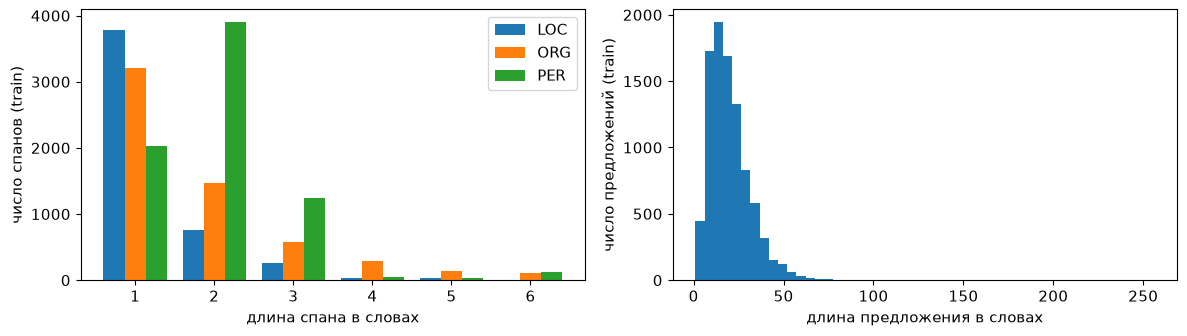

In [14]:
def word_spans(tags):
    spans, i = [], 0
    while i < len(tags):
        if tags[i] == 'O':
            i += 1
            continue
        kind, j = tags[i][2:], i + 1
        while j < len(tags) and tags[j] == 'I-' + kind:
            j += 1
        spans.append((i, j, kind))
        i = j
    return spans


types = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
span_lengths = {t: collections.Counter() for t in types}
print(f'{"split":<12}{"предл.":>8}{"слов":>8}' + ''.join(f'{t:>7}' for t in types) + f'{"всего":>8}{"на предл.":>11}{"без сущн.":>11}')
for split, ds in raw.items():
    counts, empty = collections.Counter(), 0
    for tags in ds['ner_tags']:
        spans = word_spans([LABEL_NAMES[i] for i in tags])
        empty += not spans
        for s, e, t in spans:
            counts[t] += 1
            if split == 'train':
                span_lengths[t][e - s] += 1
    n_words = sum(map(len, ds['tokens']))
    total = sum(counts.values())
    print(f'{split:<12}{len(ds):>8}{n_words:>8}' + ''.join(f'{counts[t]:>7}' for t in types)
          + f'{total:>8}{total / len(ds):>11.2f}{empty / len(ds):>11.1%}')

lengths = np.array([len(ws) for ws in raw['train']['tokens']])
print(f'длина предложения в словах (train): медиана {np.median(lengths):.0f}, 95% {np.percentile(lengths, 95):.0f}, макс {lengths.max()}')
for t in types:
    c = span_lengths[t]
    print(t, 'длины спанов:', dict(sorted(c.items())), f'среднее {sum(k * v for k, v in c.items()) / sum(c.values()):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
width = 0.8 / len(types)
for k, t in enumerate(types):
    xs = np.arange(1, 7)
    axes[0].bar(xs + (k - 1) * width, [span_lengths[t][x] for x in xs], width, label=t)
axes[0].set_xlabel('длина спана в словах')
axes[0].set_ylabel('число спанов (train)')
axes[0].legend()
axes[1].hist(lengths, bins=50)
axes[1].set_xlabel('длина предложения в словах')
axes[1].set_ylabel('число предложений (train)')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 собран из новостей коллекции Persons-1000, где изначально были размечены только персоны. Метки ORG и LOC добавляли вручную в Brat по правилам, близким к MUC-7, а перевод в IOB2 и разбиение на сплиты сделала команда DeepPavlov. В карточке лицензия `other`, раздел Licensing пустой. Типов три: PER 7406 / 1641 / 1570, ORG 5960 / 1308 / 1256, LOC 4881 / 1168 / 1175 (train / validation / test), совсем редких нет. У ORG спаны длиннее всего (до 18 слов), у LOC 78% спанов из одного слова. Медиана длины предложения 18 слов, но максимум 256, такие хвосты обрежутся по `MAX_LENGTH`.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, kind = [], None, None
    for i, tag in enumerate(list(tags) + ['O']):
        prefix, _, t = tag.partition('-')
        if start is not None and (prefix != 'I' or t != kind):
            spans.append((start, i, kind))
            start = None
        if prefix == 'B' or (prefix == 'I' and start is None):
            start, kind = i, t
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start:end] = ['B-' + kind] + ['I-' + kind] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
Path('data').mkdir(exist_ok=True)
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            f.write(json.dumps(dict(id=ex['id'], tokens=ex['tokens'], spans=spans), ensure_ascii=False) + '\n')
    with path.open(encoding='utf-8') as f:
        back = [json.loads(line) for line in f]
    n_same = n_orphan = 0
    for ex, rec in zip(ds, back, strict=True):
        tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
        bio = spans_to_bio([tuple(s) for s in rec['spans']], len(rec['tokens']))
        assert rec['id'] == ex['id'] and rec['tokens'] == ex['tokens']
        assert bio_to_spans(bio) == bio_to_spans(tags)
        n_same += bio == tags
        n_orphan += any(t.startswith('I-') and (i == 0 or tags[i - 1][2:] != t[2:]) for i, t in enumerate(tags))
    bad_words = sum(not w.strip() or any(c.isspace() for c in w) for ws in ds['tokens'] for w in ws)
    print(f'{split:<11} {len(ds)} предложений, BIO совпало дословно {n_same}, с I-X без B-X {n_orphan}, слов с пробелами или пустых {bad_words}')
print(json.dumps(back[0], ensure_ascii=False)[:300])

train       9301 предложений, BIO совпало дословно 9296, с I-X без B-X 5, слов с пробелами или пустых 0
validation  2153 предложений, BIO совпало дословно 2153, с I-X без B-X 0, слов с пробелами или пустых 0


test        1922 предложений, BIO совпало дословно 1921, с I-X без B-X 1, слов с пробелами или пустых 0
{"id": "0", "tokens": ["А", ".", "Силуанов", "назначен", "управляющим", "от", "России", "в", "МВФ"], "spans": [[0, 3, "PER"], [6, 7, "LOC"], [8, 9, "ORG"]]}


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъектам          19  O
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка нужна одна на слово, а метрика считается по словам. Если размечать все сабворды, длинные слова получат больший вес в loss. Метка -100 совпадает с `ignore_index` у cross-entropy, поэтому такие позиции не входят ни в loss, ни в градиент. В train обрезано 10 предложений (около 0.1%), из 434 потерянных слов 430 за обрезкой. Ещё 4 слова без сабвордов это мягкие переносы `\xad`, токенизатор их выбрасывает. Такие слова в предсказании получают `O`, и сущности в хвостах длинных предложений станут пропусками, но на метрику это почти не влияет. Датасет уже в BIO, проверка туда-обратно через `data/<split>_spans.jsonl` совпала по спанам везде. Дословно BIO не совпал в 5 предложениях train и одном test, там `I-X` без `B-X`.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(tagger, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, majority_pred)

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
del random_model

entity_words = [w for ws, ts in zip(val_tokens, val_gold) for w, t in zip(ws, ts) if t != 'O']
print(f'слов сущностей в validation: {len(entity_words)}, из них не встречались в train: {np.mean([w not in tagger for w in entity_words]):.1%}')
print('majority', {k: round(float(v), 4) for k, v in baseline['majority'].items()})
print(classification_report(val_gold, majority_pred, digits=4, zero_division=0))
print('random_head', {k: round(float(v), 4) for k, v in baseline['random_head'].items()})
print('теги случайной головы:', collections.Counter(t for ts in random_pred for t in ts).most_common())

слов сущностей в validation: 7286, из них не встречались в train: 20.4%
majority {'f1_micro': 0.5613, 'f1_macro': 0.5786, 'precision': 0.5626, 'recall': 0.5601}


              precision    recall  f1-score   support

         LOC     0.7532    0.7628    0.7580      1168
         ORG     0.5492    0.5765    0.5625      1308
         PER     0.4284    0.4028    0.4152      1641

   micro avg     0.5626    0.5601    0.5613      4117
   macro avg     0.5769    0.5807    0.5786      4117
weighted avg     0.5589    0.5601    0.5592      4117

random_head {'f1_micro': 0.0381, 'f1_macro': 0.0353, 'precision': 0.0223, 'recall': 0.1304}
теги случайной головы: [('O', 11544), ('I-PER', 11459), ('B-PER', 8688), ('I-LOC', 4833), ('B-LOC', 3053), ('I-ORG', 2511), ('B-ORG', 1768)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** У словарного бейзлайна F1 0.561 на validation. Новости много раз упоминают одни и те же сущности (Россия, США, МВД), поэтому LOC он размечает неплохо (F1 0.758). Хуже всего PER (0.415): 20.4% слов сущностей validation не встречались в train, а имена и фамилии повторяются реже названий стран и ведомств. К тому же одна и та же фамилия бывает и `B-PER`, и `I-PER` (после имени или инициала), так что самый частый тег ломает границы. У энкодера со случайной головой F1 0.038 при recall 0.130: тег `O` он ставит только 26% слов, а остальное раскидывает по `I-PER`, `B-PER` и другим тегам. Признаки энкодера осмысленные, но случайная линейная голова переводит их в случайные теги, а `I-X` без `B-X` seqeval считает началом нового спана.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
from transformers.trainer_callback import PrinterCallback

LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    for p in model.base_model.parameters():
        p.requires_grad = not freeze_encoder
    log_steps = max(1, math.ceil(len(train_ds) / batch_size) * epochs // 12)
    args = TrainingArguments(out_dir, learning_rate=lr, num_train_epochs=epochs, per_device_train_batch_size=batch_size,
                             per_device_eval_batch_size=64, weight_decay=0.01, warmup_steps=0.1, lr_scheduler_type='linear',
                             eval_strategy='steps', eval_steps=log_steps, logging_strategy='steps', logging_steps=log_steps,
                             save_strategy='no', fp16=torch.cuda.is_available(), report_to='none',
                             dataloader_pin_memory=False, disable_tqdm=True, seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok, pad_to_multiple_of=32), processing_class=tok)
    trainer.remove_callback(PrinterCallback)
    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

обучение: 76.1 c на mps, 9301 предложений, 3 эпох(а)


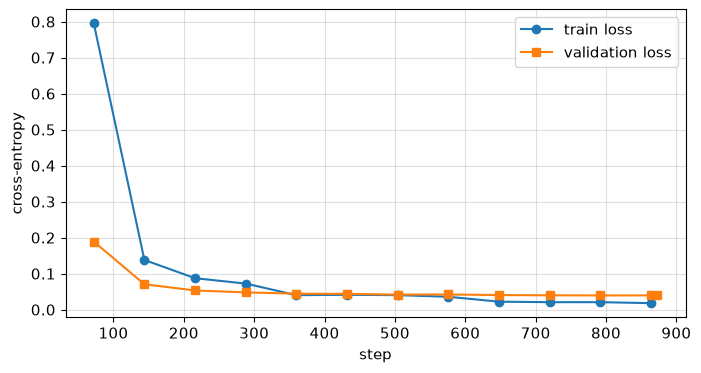

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** lr 2e-4 больше обычного для base-моделей, потому что у rubert-tiny2 маленький hidden и всего 3 слоя. Batch 32, 3 эпохи (873 шага), linear warmup на 10% шагов, затем линейное затухание, weight decay 0.01, fp16 только на CUDA. Train loss падает с 0.80 до 0.02, validation loss с 0.19 до 0.040 и примерно с 350-го шага (1.2 эпохи) стоит на плато. Validation loss не растёт, переобучения нет, а раз он стоит на плато с середины второй эпохи, больше эпох почти ничего не даст. Обучение заняло 76 с на MPS (Apple M1 Pro).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_gold = n_pred = 0
    for g_tags, p_tags in zip(gold, pred):
        for g, p in zip(g_tags, p_tags):
            n_gold += g != 'O'
            n_pred += p != 'O'
            tp += p != 'O' and p == g
    return 2 * tp / (n_gold + n_pred) if n_gold + n_pred else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
val_pred = predict_word_tags(model, val_tokens)
for name, gold, pred in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(name)
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print(f'token F1 {token_f1(gold, pred):.4f}, entity F1 micro {f1_score(gold, pred):.4f}\n')

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(entity_scores(test_gold, test_pred), token_f1=token_f1(test_gold, test_pred),
             per_type={t: {k: report[t][k] for k in ('precision', 'recall', 'f1-score', 'support')} for t in ENTITY_TYPES},
             validation=dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred)))

validation


              precision    recall  f1-score   support

         LOC     0.9527    0.9486    0.9507      1168
         ORG     0.8435    0.9021    0.8718      1308
         PER     0.9611    0.9787    0.9698      1641

   micro avg     0.9199    0.9458    0.9327      4117
   macro avg     0.9191    0.9431    0.9308      4117
weighted avg     0.9213    0.9458    0.9332      4117

token F1 0.9545, entity F1 micro 0.9327

test


              precision    recall  f1-score   support

         LOC     0.9479    0.9609    0.9544      1175
         ORG     0.8510    0.8869    0.8686      1256
         PER     0.9601    0.9815    0.9707      1570

   micro avg     0.9218    0.9458    0.9336      4001
   macro avg     0.9197    0.9431    0.9312      4001
weighted avg     0.9223    0.9458    0.9339      4001

token F1 0.9573, entity F1 micro 0.9336



**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** На test F1 по сущностям 0.934 (micro) и 0.931 (macro), P 0.922, R 0.946. Хуже всего ORG (0.869 против 0.954 у LOC и 0.971 у PER). У ORG самые длинные и разнообразные спаны: аббревиатуры, длинные официальные названия, вложенные «ГУ МВД», где граница неоднозначна. Micro и macro почти совпадают, потому что типы сбалансированы, а macro чуть ниже из-за ORG. Токенный F1 выше (0.957 против 0.934), потому что при ошибке границы seqeval теряет всю сущность, а токенный F1 засчитывает совпавшие слова. Пользователю нужна сущность целиком, так что ближе F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlaps(a, b):
        return a[0] < b[1] and b[0] < a[1]

    result = []
    for g in gold_spans:
        hits = [p for p in pred_spans if overlaps(g, p)]
        same_type = [p for p in hits if p[2] == g[2]]
        if g in pred_spans:
            result.append(('correct', g, g))
        elif same_type:
            result.append(('boundary', g, same_type[0]))
        elif hits:
            result.append(('type', g, hits[0]))
        else:
            result.append(('missed', g, None))
    result += [('spurious', None, p) for p in pred_spans if not any(overlaps(g, p) for g in gold_spans)]
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

val_results = [categorize_errors(bio_to_spans(g), bio_to_spans(p)) for g, p in zip(val_gold, val_pred)]
counts = collections.Counter(c for res in val_results for c, _, _ in res)
errors = {c: counts[c] for c in ERROR_CATEGORIES}
n_errors = sum(errors.values()) - errors['correct']
print(errors)
print('доли среди ошибок:', {c: f'{errors[c] / max(n_errors, 1):.1%}' for c in ERROR_CATEGORIES[1:]})

by_type = collections.Counter((c, (g or p)[2]) for res in val_results for c, g, p in res)
print(f'{"":<10}' + ''.join(f'{c:>10}' for c in ERROR_CATEGORIES))
for t in ENTITY_TYPES:
    print(f'{t:<10}' + ''.join(f'{by_type[c, t]:>10}' for c in ERROR_CATEGORIES))


def show_span(words, span):
    return '-' if span is None else f'[{" ".join(words[span[0]:span[1]])}] {span[2]}'


rng = random.Random(SEED)
for cat in ERROR_CATEGORIES[1:]:
    found = [(i, g, p) for i, res in enumerate(val_results) for c, g, p in res if c == cat]
    print(f'\n{cat}: {len(found)}')
    for i, g, p in rng.sample(found, min(3, len(found))):
        words = val_tokens[i]
        print(f'  {" ".join(words)[:160]}\n    gold: {show_span(words, g)}   pred: {show_span(words, p)}')

{'correct': 3894, 'boundary': 151, 'type': 49, 'missed': 23, 'spurious': 118}
доли среди ошибок: {'boundary': '44.3%', 'type': '14.4%', 'missed': '6.7%', 'spurious': '34.6%'}
             correct  boundary      type    missed  spurious
LOC             1108        19        34         7        22
ORG             1180       106         8        14        88
PER             1606        26         7         2         8

boundary: 151
  Президент назначил генерал - майора полиции Николая Мардасова начальником ГУ МВД РФ по Уральскому федеральному округу ; полковника полиции Александра Кирсанова 
    gold: [МВД] ORG   pred: [ГУ МВД] ORG
  Если недавняя отставка руководства спортивной отрасли или высших офицеров Министерства обороны и пограничного комитета ( за « плюшевый десант » ) ожидалась и пр
    gold: [Министерства обороны] ORG   pred: [Министерства обороны и пограничного комитета] ORG
  Министр иностранных дел Армении Эдвард Налбандян в рамках заседания Совета глав МИД стран Организации

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Главная категория ошибок это границы (151, 44.3% ошибок), за ней лишние спаны (118, 34.6%). На ORG приходятся 106 из 151 ошибки границ и 88 из 118 лишних спанов. Модель захватывает соседнее слово («ГУ МВД» вместо «МВД») или обрывает длинное название («Совета» вместо «Совета глав МИД»), а ошибки типа это районы с окончанием как у фамилии (Гавриловский -> PER). Часть ошибок это ошибки разметки: «ГУ МВД» вполне можно считать организацией целиком. Чтобы уменьшить ошибки границ, я бы взял модель крупнее (DistilBERT в 6.2 дал 0.958) или CRF поверх логитов и проверил разметку вложенных ORG.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'


def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


set_seed(SEED)
frozen_model = make_model()
frozen_history, RUN_TIMES['train_freeze_sec'] = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                                          freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
ablation = dict(setting=ABLATION, split='validation', variants={
    'full': dict(entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
                 eval_loss=[h['eval_loss'] for h in history if 'eval_loss' in h][-1],
                 train_sec=RUN_TIMES['train_main_sec'], trainable_params=n_trainable(model)),
    'freeze': dict(entity_scores(val_gold, frozen_pred), token_f1=token_f1(val_gold, frozen_pred),
                   eval_loss=[h['eval_loss'] for h in frozen_history if 'eval_loss' in h][-1],
                   train_sec=RUN_TIMES['train_freeze_sec'], trainable_params=n_trainable(frozen_model))})
for name, v in ablation['variants'].items():
    print(f'{name:<7}' + '  '.join(f'{k} {v[k]:.4f}' if isinstance(v[k], float) else f'{k} {v[k]:,}' for k in v))
print(classification_report(val_gold, frozen_pred, digits=4, zero_division=0))

full   f1_micro 0.9327  f1_macro 0.9308  precision 0.9199  recall 0.9458  token_f1 0.9545  eval_loss 0.0395  train_sec 76.1426  trainable_params 29,098,303
freeze f1_micro 0.6152  f1_macro 0.5967  precision 0.6323  recall 0.5990  token_f1 0.6518  eval_loss 0.2602  train_sec 33.1531  trainable_params 2,191


              precision    recall  f1-score   support

         LOC     0.7664    0.6884    0.7253      1168
         ORG     0.4479    0.3058    0.3635      1308
         PER     0.6445    0.7690    0.7013      1641

   micro avg     0.6323    0.5990    0.6152      4117
   macro avg     0.6196    0.5877    0.5967      4117
weighted avg     0.6167    0.5990    0.6008      4117



**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** С замороженным энкодером validation F1 падает с 0.933 до 0.615, токенный F1 с 0.954 до 0.652. Обучение быстрее в 2.3 раза (33 с против 76 с), обучаемых параметров 2,191 вместо 29.1M. Хуже всего ORG (0.364): линейная голова на признаках, которые энкодер не видел под NER, не различает границы длинных названий. По карточке rubert-tiny2 настраивали на эмбеддинги предложений (приближение LaBSE), и, видимо, поэтому её токенные признаки плохо разделяются линейно. Validation loss замороженной модели 0.260 против 0.040, и, возможно, голове просто не хватило шагов при lr 2e-4. Следующим шагом я бы обучил голову с lr в 10 раз больше и дольше на нескольких seed и проверил, сохранится ли разрыв.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообучение rubert-tiny2 за 76 с на M1 подняло F1 по сущностям на test до 0.934, у словарного бейзлайна на validation было 0.561, у случайной головы 0.038. Лучше всего PER (0.971) и LOC (0.954), хуже всего ORG (0.869), на них 106 из 151 ошибки границ. Заморозка энкодера не работает (0.615), дообучать нужно всю модель. Validation loss выходит на плато за 1.2 эпохи, а модель крупнее помогает: DistilBERT дал 0.958, но обучение в 6 раз дольше. Модель полностью зависит от регистра: в нижнем регистре F1 падает до 0.067. Ограничения: один seed, гиперпараметры почти не подбирались, в разметке ORG есть спорные вложенные названия. Дальше я бы проверил разброс по seed, добавил аугментацию регистра и попробовал rubert-base-cased.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "split": "validation", "variants": {"full": {"f1_micro": 0.9326946107784431, "f1_macro": 0.9307618433274943, "precision": 0.9199149539333806, "recall": 0.9458343453971338, "token_f1": 0.9544865233708631, "eval_loss": 0.0394822433590889, "train_sec": 76.14260604197625, "trainable_params": 29098303}, "freeze": {"f
final F1 micro 0.9336


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не делал.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    ALT_ID, ALT_REVISION, ALT_LR = 'distilbert/distilbert-base-multilingual-cased', '45c032ab32cc946ad88a166f7cb282f58c753c2e', 5e-5
    alt_tok = AutoTokenizer.from_pretrained(ALT_ID, revision=ALT_REVISION)
    alt_tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs=dict(tok=alt_tok))
    set_seed(SEED)
    alt_model = make_model(ALT_ID, ALT_REVISION)
    _, RUN_TIMES['train_alt_sec'] = train_ner(alt_model, alt_tokenized['train'], alt_tokenized['validation'], lr=ALT_LR,
                                              tok=alt_tok, out_dir='runs/alt')

    def timed_predict(m, tok):
        predict_word_tags(m, test_tokens[:64], tok=tok)
        start = time.perf_counter()
        pred = predict_word_tags(m, test_tokens, tok=tok)
        return pred, time.perf_counter() - start

    compare = {}
    for name, m, tok, sec in [(MODEL_ID, model, tokenizer, RUN_TIMES['train_main_sec']),
                              (ALT_ID, alt_model, alt_tok, RUN_TIMES['train_alt_sec'])]:
        pred, infer_sec = timed_predict(m, tok)
        n_sub = sum(len(tok(ws, is_split_into_words=True)['input_ids']) - 2 for ws in test_tokens)
        params = sum(p.numel() for p in m.parameters())
        compare[name] = dict(entity_scores(test_gold, pred), f1_val=f1_score(val_gold, predict_word_tags(m, val_tokens, tok=tok)),
                             params=params, size_mb=params * 4 / 2**20, train_sec=sec, test_infer_sec=infer_sec,
                             subwords_per_word=n_sub / sum(map(len, test_tokens)))
    for name, v in compare.items():
        print(name)
        print('   ' + '  '.join(f'{k} {v[k]:.4f}' if isinstance(v[k], float) else f'{k} {v[k]:,}' for k in v))
    alt_model = alt_model.cpu()

cointegrated/rubert-tiny2
   f1_micro 0.9336  f1_macro 0.9312  precision 0.9218  recall 0.9458  f1_val 0.9327  params 29,098,303  size_mb 111.0012  train_sec 76.1426  test_infer_sec 1.0814  subwords_per_word 1.1418
distilbert/distilbert-base-multilingual-cased
   f1_micro 0.9579  f1_macro 0.9562  precision 0.9525  recall 0.9633  f1_val 0.9561  params 134,739,463  size_mb 513.9903  train_sec 463.2592  test_infer_sec 7.4136  subwords_per_word 1.7315


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Многоязычный DistilBERT лучше: F1 на test 0.958 против 0.934, macro 0.956 против 0.931. Цена: в 4.6 раза больше параметров (134.7M против 29.1M, 514 МБ против 111 МБ в fp32), обучение в 6.1 раза дольше (463 с против 76 с), инференс test в 6.9 раза дольше (7.4 с против 1.1 с на MPS). К тому же его словарь режет русские слова мельче (1.73 сабворда на слово против 1.14). Сравнение одинаковое по данным, сплитам, `MAX_LENGTH`, числу эпох, batch, seed, расписанию lr и оценке по первому сабворду. Отличается только lr (5e-5, стандартный для base, против 2e-4), отдельно его ни для одной модели не подбирал. Взял DistilBERT, а не 12-слойную base-модель, чтобы обучение на M1 уложилось в несколько минут.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    TRANSLIT = dict(zip('абвгдеёзийклмнопрстуфхыэ', 'abvgdeeziiklmnoprstufhye'))
    TRANSLIT.update(ж='zh', ц='ts', ч='ch', ш='sh', щ='sch', ъ='', ь='', ю='yu', я='ya')

    def translit(word):
        out = ''.join(TRANSLIT.get(c.lower(), c.lower()).capitalize() if c.isupper() else TRANSLIT.get(c, c) for c in word)
        return out or word

    def typo(word, rng):
        if len(word) < 4 or rng.random() > 0.3:
            return word
        i = rng.randrange(1, len(word) - 1)
        op = rng.choice(['swap', 'drop', 'double'])
        if op == 'swap':
            return word[:i] + word[i + 1] + word[i] + word[i + 2:]
        if op == 'drop':
            return word[:i] + word[i + 1:]
        return word[:i] + word[i] + word[i:]

    typo_rng = random.Random(SEED)
    corruptions = {
        'clean': lambda w: w,
        'lower': str.lower,
        'upper': str.upper,
        'typos 30%': lambda w: typo(w, typo_rng),
        'translit': translit,
    }
    shift = {}
    for name, fn in corruptions.items():
        tokens = [[fn(w) for w in ws] for ws in val_tokens]
        pred = predict_word_tags(model, tokens)
        rep = classification_report(val_gold, pred, output_dict=True, zero_division=0)
        shift[name] = dict(f1=f1_score(val_gold, pred), **{t: rep[t]['f1-score'] for t in ENTITY_TYPES})
        print(f'{name:<10} F1 {shift[name]["f1"]:.4f}  ' + '  '.join(f'{t} {shift[name][t]:.4f}' for t in ENTITY_TYPES)
              + f'   пример: {" ".join(tokens[1][:8])}')

clean      F1 0.9327  LOC 0.9507  ORG 0.8718  PER 0.9698   пример: Президент США Барак Обама в пятницу , 19


lower      F1 0.0672  LOC 0.0212  ORG 0.0658  PER 0.0984   пример: президент сша барак обама в пятницу , 19


upper      F1 0.0732  LOC 0.1592  ORG 0.0546  PER 0.0058   пример: ПРЕЗИДЕНТ США БАРАК ОБАМА В ПЯТНИЦУ , 19


typos 30%  F1 0.8663  LOC 0.8873  ORG 0.8030  PER 0.9016   пример: Президент США Барак Обама в пятницу , 19


translit   F1 0.1227  LOC 0.0153  ORG 0.0883  PER 0.2449   пример: Prezident SShA Barak Obama v pyatnitsu , 19


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего роняет F1 регистр: в нижнем регистре 0.067, в верхнем 0.073, транслит 0.123, опечатки в 30% длинных слов только 0.866 (было 0.933). Модель cased, и заглавная буква для неё главный признак сущности. В нижнем регистре этот признак пропадает, а в верхнем все слова выглядят как аббревиатуры (PER падает до 0.006). Транслит переводит слова в латиницу, которой в русских новостях пишутся в основном названия компаний, и словарь режет такие слова на мелкие куски. Опечатки портят одно-два слова в предложении, а остальные сабворды сохраняются, поэтому падение небольшое.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import importlib.util
    import inspect
    import logging
    import subprocess
    import sys
    import types
    import warnings
    if importlib.util.find_spec('onnxruntime') is None or importlib.util.find_spec('onnxscript') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnx', 'onnxruntime', 'onnxscript'], check=True)
    import onnxruntime as ort
    from onnxruntime.quantization import QuantType, quantize_dynamic

    logging.getLogger().setLevel(logging.ERROR)
    cpu_model = copy.deepcopy(model).cpu().eval()
    batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True,
                      return_tensors='pt')
    input_names = [k for k in inspect.signature(cpu_model.forward).parameters if k in batch]
    onnx_path, int8_path = Path('runs/ner.onnx'), Path('runs/ner_int8.onnx')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        torch.onnx.export(cpu_model, (), onnx_path, kwargs={k: batch[k] for k in input_names}, input_names=input_names,
                          output_names=['logits'], dynamo=False,
                          dynamic_axes={k: {0: 'batch', 1: 'seq'} for k in input_names + ['logits']})
        quantize_dynamic(onnx_path, int8_path, weight_type=QuantType.QInt8)

    class OrtModel:
        def __init__(self, path, config):
            self.session = ort.InferenceSession(str(path), providers=['CPUExecutionProvider'])
            self.inputs = [i.name for i in self.session.get_inputs()]
            self.config = config

        def eval(self):
            return self

        def to(self, dev):
            return self

        def __call__(self, **enc):
            logits = self.session.run(None, {k: enc[k].cpu().numpy() for k in self.inputs})[0]
            return types.SimpleNamespace(logits=torch.from_numpy(logits))

    def latency_ms(m, n=20):
        x = {k: v for k, v in batch.items()}
        with torch.inference_mode():
            for _ in range(3):
                m(**x)
            times = []
            for _ in range(n):
                start = time.perf_counter()
                m(**x)
                times.append(time.perf_counter() - start)
        return 1000 * float(np.mean(times)), 1000 * float(np.std(times))

    cpu = torch.device('cpu')
    speed = {}
    for name, m, path in [('torch fp32', cpu_model, None), ('onnx fp32', OrtModel(onnx_path, model.config), onnx_path),
                          ('onnx int8', OrtModel(int8_path, model.config), int8_path)]:
        mean, std = latency_ms(m)
        pred = predict_word_tags(m, val_tokens, dev=cpu)
        size = path.stat().st_size / 2**20 if path else sum(p.numel() for p in cpu_model.parameters()) * 4 / 2**20
        speed[name] = dict(latency_ms=mean, std_ms=std, f1_val=f1_score(val_gold, pred), size_mb=size)
    print(f'CPU {os.uname().machine}, torch threads {torch.get_num_threads()}, батч {tuple(batch["input_ids"].shape)}')
    for name, v in speed.items():
        print(f'{name:<11} {v["latency_ms"]:7.2f} +- {v["std_ms"]:.2f} ms  x{speed["torch fp32"]["latency_ms"] / v["latency_ms"]:.2f}'
              f'  F1 val {v["f1_val"]:.4f}  {v["size_mb"]:.1f} MB')

CPU arm64, torch threads 6, батч (32, 48)
torch fp32    16.73 +- 0.67 ms  x1.00  F1 val 0.9327  111.0 MB
onnx fp32     30.20 +- 0.44 ms  x0.55  F1 val 0.9327  111.1 MB
onnx int8     16.60 +- 1.06 ms  x1.01  F1 val 0.9330  27.9 MB


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** На CPU Apple M1 Pro (6 потоков, батч 32 x 48) ускорения нет. torch fp32 16.7 мс, ONNX fp32 30.2 мс (в 1.8 раза медленнее), ONNX int8 16.6 мс (x1.01). F1 на validation не упал: 0.9327 у ONNX fp32 и 0.9330 у int8. Квантизация уменьшила файл в 4 раза (111 -> 28 МБ). У rubert-tiny2 92% параметров в эмбеддингах, а это поиск по таблице без вычислений, и на энкодер приходится всего 2.3M параметров. Поэтому время уходит на накладные расходы, а не на матричные умножения, и ускорять почти нечего. У base-моделей основная часть вычислений в слоях энкодера, и для них выигрыш от int8, скорее всего, будет заметнее.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean  порог 0: P 0.9199 R 0.9458 F1 0.9327   лучший порог 0.82: P 0.9468 R 0.9286 F1 0.9376


min   порог 0: P 0.9199 R 0.9458 F1 0.9327   лучший порог 0.64: P 0.9385 R 0.9373 F1 0.9379


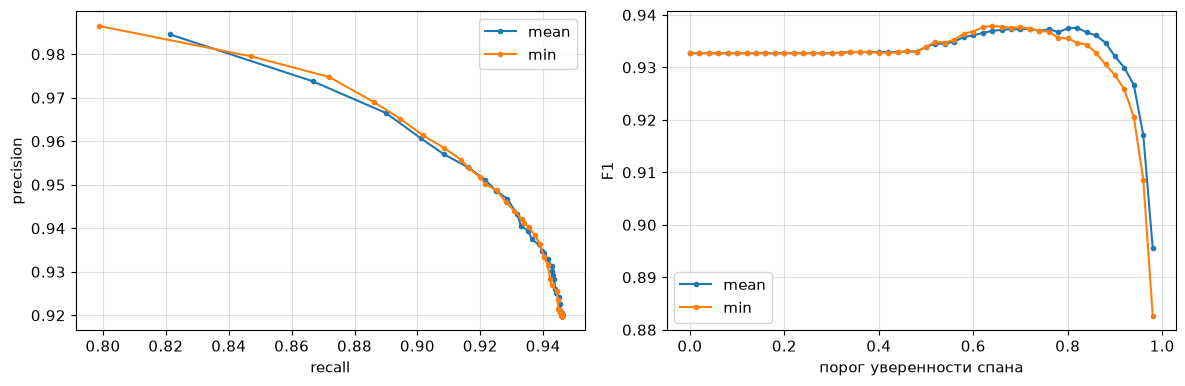

In [34]:
if '6.5' in BONUS_TASKS:
    conf_tags, conf_probs = predict_word_tags(model, val_tokens, return_probs=True)
    thresholds = np.round(np.arange(0, 1, 0.02), 2)
    curves = {}
    for how, agg in [('mean', np.mean), ('min', np.min)]:
        rows = []
        for thr in thresholds:
            pred = [spans_to_bio([s for s in bio_to_spans(tags) if agg(probs[s[0]:s[1]]) >= thr], len(tags))
                    for tags, probs in zip(conf_tags, conf_probs)]
            rows.append((precision_score(val_gold, pred, zero_division=0), recall_score(val_gold, pred, zero_division=0),
                         f1_score(val_gold, pred, zero_division=0)))
        curves[how] = np.array(rows)
        best = int(curves[how][:, 2].argmax())
        print(f'{how:<5} порог 0: P {rows[0][0]:.4f} R {rows[0][1]:.4f} F1 {rows[0][2]:.4f}   '
              f'лучший порог {thresholds[best]:.2f}: P {rows[best][0]:.4f} R {rows[best][1]:.4f} F1 {rows[best][2]:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for how, c in curves.items():
        axes[0].plot(c[:, 1], c[:, 0], '.-', label=how)
        axes[1].plot(thresholds, c[:, 2], '.-', label=how)
    axes[0].set_xlabel('recall')
    axes[0].set_ylabel('precision')
    axes[1].set_xlabel('порог уверенности спана')
    axes[1].set_ylabel('F1')
    for ax in axes:
        ax.grid(True, alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Для средней уверенности лучший порог 0.82: F1 0.9376 против 0.9327 при пороге 0 (+0.5 п.п., P 0.920 -> 0.947, R 0.946 -> 0.929). Для минимальной лучший порог 0.64 и F1 0.9379. Минимальная строже: одно неуверенное слово отбрасывает весь спан, поэтому её оптимальный порог ниже. Средняя прощает одно слабое слово в длинном спане. Порог только убирает предсказанные спаны и не добавляет новых, поэтому recall может только падать. Порог подобран на validation, так что прирост оптимистичен и его надо проверить на test.